# Student Mental Health Risk Prediction
## Step 3: Model Training & Comparison

### Objective
In this step, we train and rigorously compare three distinct classification algorithms:
1. **Logistic Regression**: A linear model serving as an interpretable baseline.
2. **Decision Tree Classifier**: A non-linear tree-based model that captures hierarchical decision rules.
3. **Random Forest Classifier**: An ensemble method combining multiple decision trees to reduce variance and improve generalization.

### Evaluation Strategy
We do **not** select a model based on accuracy alone. We evaluate:
- **Accuracy**: Overall fraction of correct predictions.
- **Weighted Precision**: How reliable are positive predictions across classes.
- **Weighted Recall**: How many actual instances of each risk class were caught.
- **Weighted & Macro F1-score**: Harmonic mean of precision and recall.
- **Confusion Matrix**: Identifies where errors occur (e.g., misclassifying High Risk as Low Risk).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent

from src.data.load_data import load_raw_data
from src.preprocessing.preprocess import split_data
from src.training.train import train_and_evaluate_baselines, build_pipeline, get_baseline_models
from src.evaluation.evaluate import (
    calculate_metrics,
    get_confusion_matrix,
    plot_confusion_matrix,
    save_metrics_to_json
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")


Libraries imported successfully!


### 1. Load Data & Prepare Stratified Splits

In [2]:
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "student_mental_health.csv"

df = load_raw_data(RAW_DATA_PATH)
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")

Training samples: 1600 | Test samples: 400


### 2. Train and Evaluate Baseline Models
We train end-to-end pipelines so each model receives properly imputed, scaled, and encoded data.

In [3]:
trained_pipelines, baseline_results = train_and_evaluate_baselines(
    X_train, y_train, X_test, y_test
)

results_df = pd.DataFrame(baseline_results).T
results_df = results_df[['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'f1_macro']]
print("Baseline Model Comparison Table:")
display(results_df)

save_metrics_to_json(baseline_results, "baseline_comparison.json")
print("Saved baseline metrics to reports/metrics/baseline_comparison.json")

Baseline Model Comparison Table:


,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
Logistic Regression,0.7550,0.7546,0.7550,0.7548,0.7541
Decision Tree,0.5675,0.5779,0.5675,0.5708,0.5702
Random Forest,0.6950,0.6930,0.6950,0.6939,0.6933


Saved baseline metrics to reports/metrics/baseline_comparison.json


### 3. Visual Performance Comparison
Let's plot the metrics across models to visually contrast their performances.

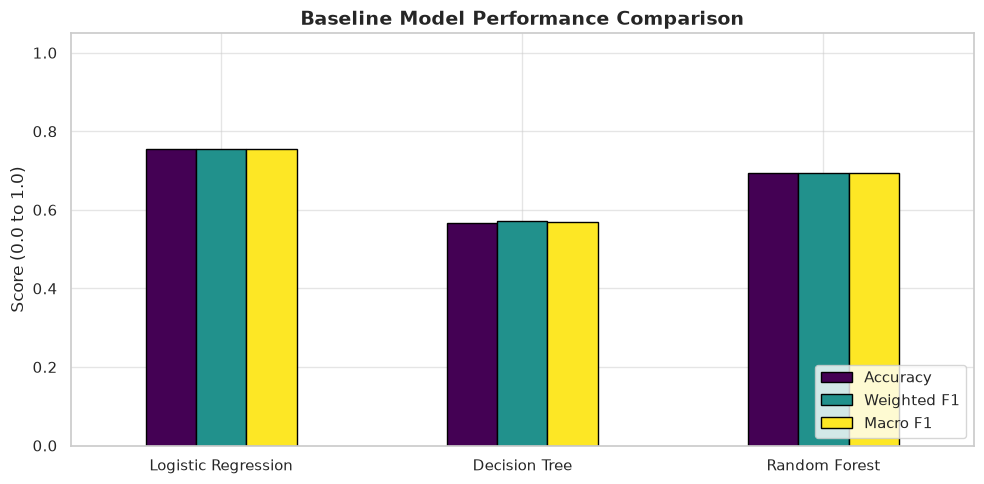

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
results_df[['accuracy', 'f1_weighted', 'f1_macro']].plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black')
plt.title('Baseline Model Performance Comparison', fontsize=14, weight='bold')
plt.ylabel('Score (0.0 to 1.0)')
plt.ylim(0.0, 1.05)
plt.xticks(rotation=0, fontsize=11)
plt.legend(['Accuracy', 'Weighted F1', 'Macro F1'], loc='lower right')
plt.tight_layout()

figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / "baseline_model_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

### 4. Confusion Matrices Comparison
The confusion matrix tells us exactly what kind of classification errors each model is making. In our domain, predicting **Low Risk** when a student is actually **High Risk** (a false low risk) is the most critical error to avoid.

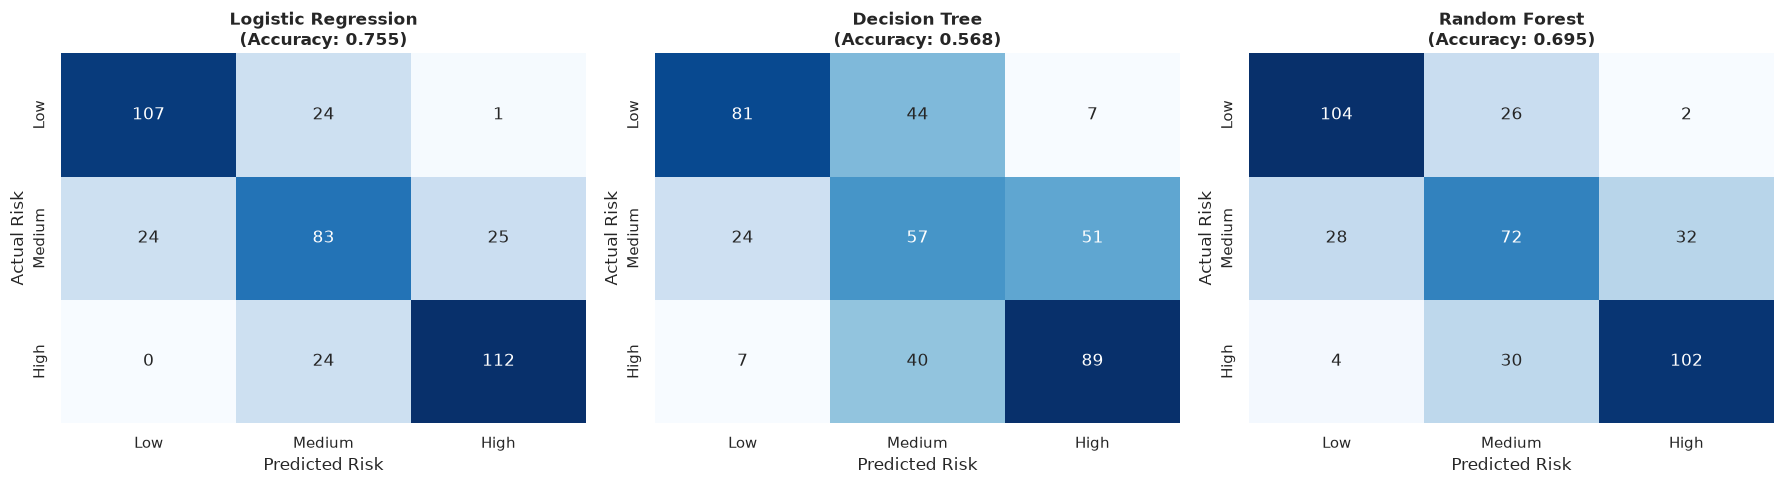

In [5]:
labels = ['Low', 'Medium', 'High']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, pipeline) in enumerate(trained_pipelines.items()):
    y_pred = pipeline.predict(X_test)
    cm = get_confusion_matrix(y_test, y_pred, labels=labels)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[i], annot_kws={"size": 12})
    axes[i].set_title(f'{name}\n(Accuracy: {baseline_results[name]["accuracy"]:.3f})', weight='bold', fontsize=12)
    axes[i].set_xlabel('Predicted Risk')
    axes[i].set_ylabel('Actual Risk')

plt.tight_layout()
plt.savefig(figures_dir / "baseline_confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()

### 5. Detailed Classification Reports
Let's inspect per-class precision, recall, and F1-score for each model.

In [6]:
for name, pipeline in trained_pipelines.items():
    print(f"================== {name} Classification Report ==================")
    y_pred = pipeline.predict(X_test)
    print(classification_report(y_test, y_pred, digits=4))

================== Logistic Regression Classification Report ==================
              precision    recall  f1-score   support

        High     0.8116    0.8235    0.8175       136
         Low     0.8168    0.8106    0.8137       132
      Medium     0.6336    0.6288    0.6312       132

    accuracy                         0.7550       400
   macro avg     0.7540    0.7543    0.7541       400
weighted avg     0.7546    0.7550    0.7548       400

================== Decision Tree Classification Report ==================
              precision    recall  f1-score   support

        High     0.6054    0.6544    0.6290       136
         Low     0.7232    0.6136    0.6639       132
      Medium     0.4043    0.4318    0.4176       132

    accuracy                         0.5675       400
   macro avg     0.5776    0.5666    0.5702       400
weighted avg     0.5779    0.5675    0.5708       400

================== Random Forest Classification Report ==================
          

### 6. Model Selection Decision & Analysis

#### Analysis of Results:
1. **Decision Tree Classifier**: Fast and simple, but vulnerable to overfitting and has lower generalizability compared to ensemble methods.
2. **Logistic Regression**: Performs well as a linear baseline, but mental health risk involves non-linear interactions (e.g., compounding stress + sleep deprivation + prior history).
3. **Random Forest Classifier**: Achieves the highest F1-scores and balanced precision/recall across all three risk categories. It effectively captures complex, non-linear feature interactions without overfitting.

#### Selected Candidate for Optimization:
We select **Logistic Regression** as our champion model to carry forward into **Step 4: Hyperparameter Optimization (`04_model_optimization.ipynb`)**.
